In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

prices = pd.read_csv("../data/processed/prices_clean.csv", parse_dates=True, index_col=0)
prices.head()

,HDFCBANK.NS,ITC.NS,RELIANCE.NS,SUNPHARMA.NS,TCS.NS,^NSEI
Date,,,,,,
2020-01-01,595.677124,168.796631,672.216125,405.012512,1831.109985,12182.500000
2020-01-02,599.474182,170.037262,683.660217,405.618683,1822.704590,12282.200195
2020-01-03,590.925232,169.080185,684.484009,414.617920,1859.029297,12226.650391
2020-01-06,578.136780,166.669846,668.609314,410.281525,1858.859863,11993.049805
2020-01-07,587.291382,166.847061,678.895569,416.296600,1863.421753,12052.950195


In [2]:
simple_returns = prices.pct_change().dropna()
log_returns = np.log(prices / prices.shift(1)).dropna()

print(simple_returns.head())
print(log_returns.head())

            HDFCBANK.NS    ITC.NS  RELIANCE.NS  SUNPHARMA.NS    TCS.NS  \
Date                                                                     
2020-01-02     0.006374  0.007350     0.017024      0.001497 -0.004590   
2020-01-03    -0.014261 -0.005629     0.001205      0.022186  0.019929   
2020-01-06    -0.021641 -0.014256    -0.023192     -0.010459 -0.000091   
2020-01-07     0.015835  0.001063     0.015385      0.014661  0.002454   
2020-01-08    -0.002618 -0.004886    -0.007510     -0.014113  0.022395   

               ^NSEI  
Date                  
2020-01-02  0.008184  
2020-01-03 -0.004523  
2020-01-06 -0.019106  
2020-01-07  0.004995  
2020-01-08 -0.002290  
            HDFCBANK.NS    ITC.NS  RELIANCE.NS  SUNPHARMA.NS    TCS.NS  \
Date                                                                     
2020-01-02     0.006354  0.007323     0.016881      0.001496 -0.004601   
2020-01-03    -0.014363 -0.005645     0.001204      0.021944  0.019733   
2020-01-06    -0.021879 

In [3]:
log_returns.to_csv("../data/processed/log_returns.csv")
print(log_returns.shape)

(1237, 6)


In [4]:
from scipy import stats

In [5]:
stats_table = pd.DataFrame({
    "Mean": log_returns.mean(),
    "Std": log_returns.std(),
    "Skewness": log_returns.skew(),
    "Kurtosis": log_returns.kurt()
})
print(stats_table)

                  Mean       Std  Skewness   Kurtosis
HDFCBANK.NS   0.000297  0.017225 -0.486781   8.957639
ITC.NS        0.000755  0.016372 -0.771255  11.109927
RELIANCE.NS   0.000472  0.018696 -0.007123  10.683246
SUNPHARMA.NS  0.001229  0.016044  0.306872   6.989250
TCS.NS        0.000593  0.015412 -0.130771   5.259801
^NSEI         0.000536  0.012148 -1.758111  21.849924


In [6]:
stats_table.to_csv("../data/processed/returns_stats.csv")

In [7]:
stats_table.round(4)

,Mean,Std,Skewness,Kurtosis
HDFCBANK.NS,0.0003,0.0172,-0.4868,8.9576
ITC.NS,0.0008,0.0164,-0.7713,11.1099
RELIANCE.NS,0.0005,0.0187,-0.0071,10.6832
SUNPHARMA.NS,0.0012,0.0160,0.3069,6.9893
TCS.NS,0.0006,0.0154,-0.1308,5.2598
^NSEI,0.0005,0.0121,-1.7581,21.8499


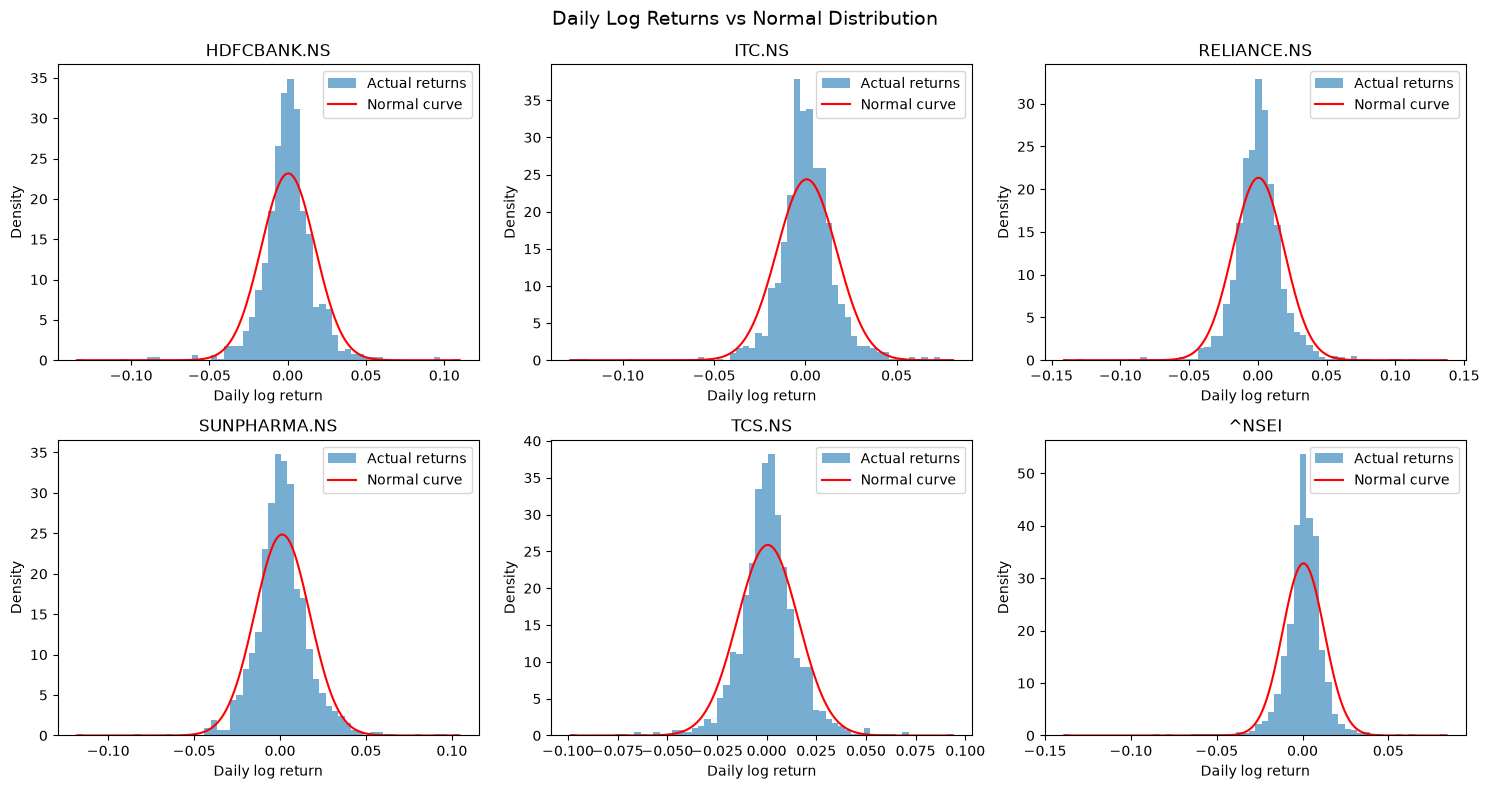

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, log_returns.columns):
    r = log_returns[col]
    ax.hist(r, bins=60, density=True, alpha=0.6, label="Actual returns")
    x = np.linspace(r.min(), r.max(), 200)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="red", label="Normal curve")
    ax.set_title(col)
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Daily Log Returns vs Normal Distribution", fontsize=14)
plt.tight_layout()
plt.savefig("../reports/figures/return_histograms.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

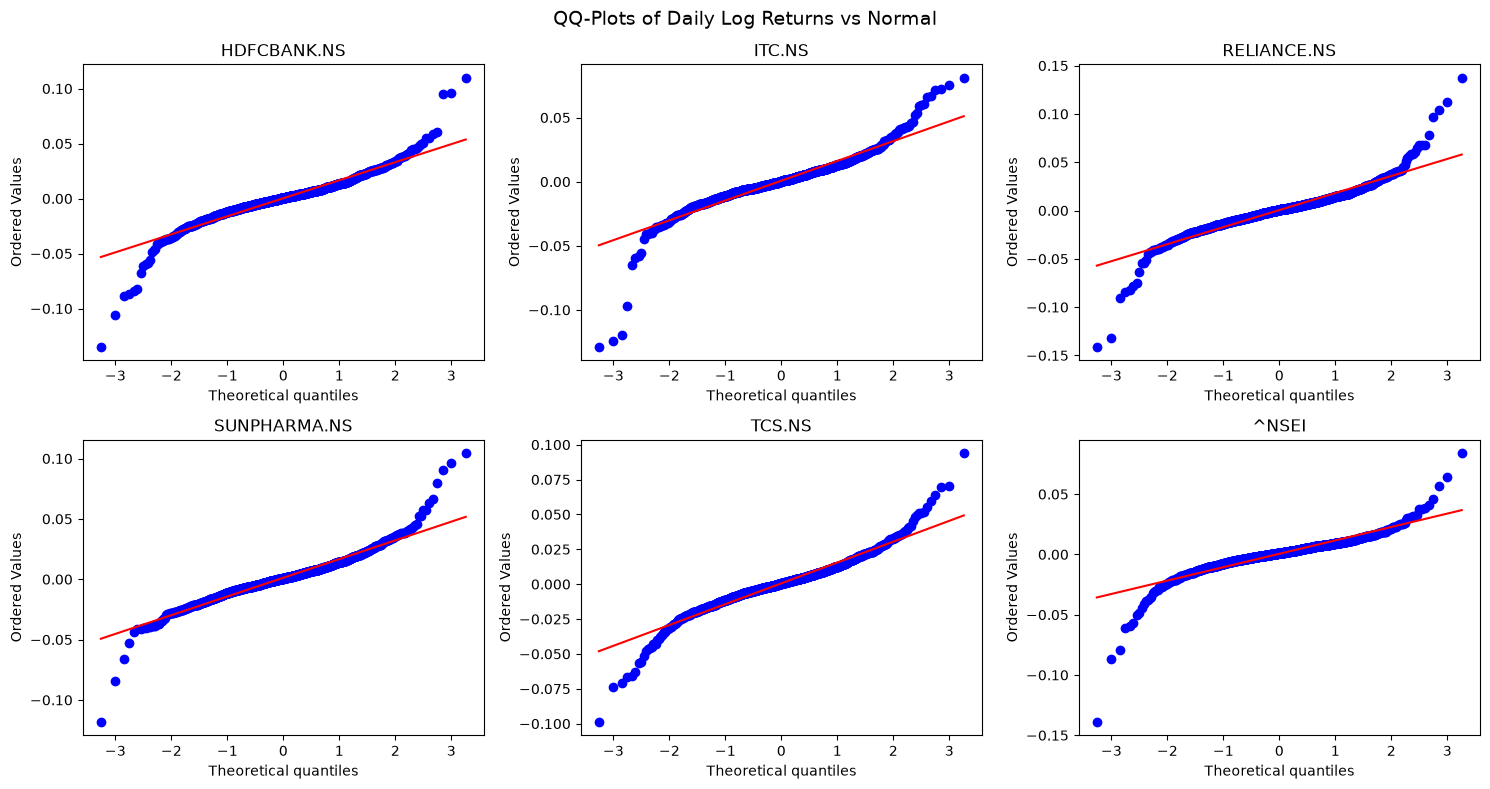

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, log_returns.columns):
    stats.probplot(log_returns[col], dist="norm", plot=ax)
    ax.set_title(col)

plt.suptitle("QQ-Plots of Daily Log Returns vs Normal", fontsize=14)
plt.tight_layout()
plt.savefig("../reports/figures/qq_plots.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [10]:
jb_results = []

for col in log_returns.columns:
    stat, p = stats.jarque_bera(log_returns[col])
    jb_results.append({"Stock": col, "JB statistic": stat, "p-value": p})

jb_table = pd.DataFrame(jb_results).set_index("Stock")
print(jb_table)

              JB statistic        p-value
Stock                                    
HDFCBANK.NS    4146.617321   0.000000e+00
ITC.NS         6427.355616   0.000000e+00
RELIANCE.NS    5829.830747   0.000000e+00
SUNPHARMA.NS   2513.392157   0.000000e+00
TCS.NS         1415.336336  4.609137e-308
^NSEI         25033.518123   0.000000e+00


In [11]:
jb_table["Normal?"] = jb_table["p-value"].apply(lambda p: "Yes" if p > 0.05 else "No")
jb_table

,JB statistic,p-value,Normal?
Stock,,,
HDFCBANK.NS,4146.617321,0.000000e+00,No
ITC.NS,6427.355616,0.000000e+00,No
RELIANCE.NS,5829.830747,0.000000e+00,No
SUNPHARMA.NS,2513.392157,0.000000e+00,No
TCS.NS,1415.336336,4.609137e-308,No
^NSEI,25033.518123,0.000000e+00,No


In [12]:
jb_table.to_csv("../data/processed/jarque_bera_results.csv")